In [1]:
using Revise
using LinearAlgebra
using Plots
using LaTeXStrings

In [2]:
BLAS.set_num_threads(1)

In [3]:
gr();
# pyplot();
# plotlyjs();

In [4]:
using GaussianSpectralDensities

# Dynamics of a random neural network with one planted memory

$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
$$

$$
\begin{aligned}
\frac{d x_i}{dt} &= -x_i + \sum_{j = 1}^N \tilde{J}_{ij} \tanh x_j \ , \\
\tilde{J} &= \frac{\hat{\bm{x}} \tanh \hat{\bm{x}}}{\|\tanh \hat{\bm{x}}\|^2} + \sigma J \, , \\
\langle J_{ij} J_{kl} \rangle &= \frac{1}{N} \left(\delta_{ik} \delta_{jl} + \tau \delta_{il} \delta_{kj} \right) \, .
\end{aligned}
$$

The memory $\hat{\bm{x}}$ is a randomly sampled vector, and the model
is set up such that, in the absence of coupling noise ($\sigma = 0$),
there is a fixed point at $\bm{x} = \hat{\bm{x}}$. What happens as
noise is turned on, and what is the effect of symmetry $\tau$?

Note that the $\tanh$ breaks rotational symmetry, so different
$\hat{\bm{x}}$ with the same norm do not necessarily give equivalent
dynamics. Should this inform our choice of measure for sampling
memories? No, I think sampling something like a Gaussian $\hat{\bm{x}}$
is the most sensible approach. It maintains permutation invariance
but not full rotational invariance, which actually seems desirable in
a nonlinear model.

Let's run some simulations.

In [5]:
function network_f!(dx, x, J̃, t)
    mul!(dx, J̃, tanh.(x))
    dx .-= x
end

function network_jac!(jac, x, J̃, t)
    for j in 1:length(x)
        for i in 1:length(x)
            jac[i, j] = J̃[i, j] / (cosh(x[j])^2)
        end
        jac[j, j] -= 1.0
    end
end

function poor_mans_network_jac!(jac, x, J̃, t, dx)
    xx = copy(x)
    fx = similar(xx)
    fxdx = similar(xx)
    network_f!(fx, xx, J̃, t)
    for j in 1:N
        xx[j] += dx
        network_f!(fxdx, xx, J̃, t) 
        jac[:, j] = (fxdx - fx) / dx
        xx[j] = x[j]
    end
end

poor_mans_network_jac! (generic function with 1 method)

In [6]:
N = 256
s = 1.0
x̂ = s * randn(N)
tx̂ = tanh.(x̂)
Ĵ = x̂ * tx̂' / dot(tx̂, tx̂)
Ĵ[diagind(Ĵ)] .= 0.0;

In [7]:
σ = 0.511
τ = 0.5

J = (1 / sqrt(N)) * randn(N, N)
J = SamplingUtils.partially_hermitize(J, τ)
J[diagind(J)] .= 0.0

J̃ = Ĵ + σ * J;

In [8]:
# Verify Jacobian
jaca = similar(J̃)
jacb = similar(J̃)
network_jac!(jaca, x̂, J̃, 0.0)
poor_mans_network_jac!(jacb, x̂, J̃, 0.0, 1e-6)
opnorm(jacb - jaca)

4.999246078206122e-7

In [9]:
using NLsolve

sol = nlsolve(
    (dx, x) -> network_f!(dx, x, J̃, 0.0),
    (jac, x) -> network_jac!(jac, x, J̃, 0.0),
    x̂;
    method=:newton,
)
if !converged(sol)
    error("failed to converge")
end
x₀ = sol.zero
jac = similar(J̃)
network_jac!(jac, x₀, J̃, 0.0)
jacevs = eigvals(jac)
println(maximum(real(jacevs)))

-0.5327449575294998


In [10]:
R = Diagonal(cosh.(x₀).^(-2))
ensemble = MatrixEnsemble(Ĵ * R - I, σ * I(N), R, τ)
Mevs = unique(eigvals(ensemble.M))
Aevs = eigvals(
    ensemble.M + (
        ensemble.L
        * SamplingUtils.partially_hermitize((1 / sqrt(N)) * randn(N, N), ensemble.T[1]^2)
        * ensemble.R
    )
);

In [11]:
using LazySets: VPolygon, Bloating, overapproximate, radius

coords = reinterpret(Float64, reshape(Aevs, 1, :))
region = VPolygon(coords)
region = Bloating(region, 0.125 * radius(region))
region = overapproximate(region, 0.01 * radius(region))
bounds = overapproximate(region)

xcenter, ycenter = bounds.center
xradius, yradius = bounds.radius
xmin, xmax = xcenter - xradius, xcenter + xradius
ymin, ymax = ycenter - yradius, ycenter + yradius
xs = range(xmin, xmax; length=round(Int, 128 * xradius))
ys = range(ymin, ymax; length=round(Int, 128 * yradius));

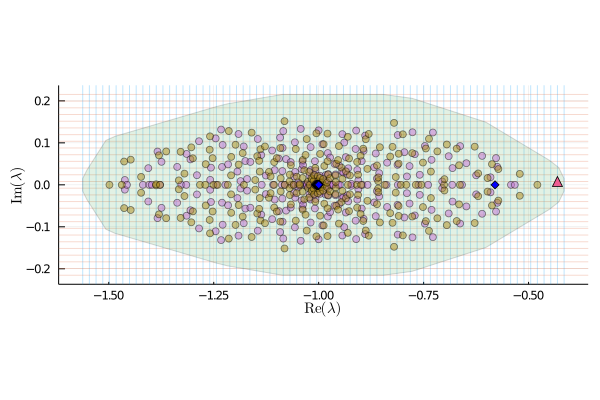

In [12]:
p = vline(xs, label="", alpha=0.25, xlims=(xs[1], xs[end]))
hline!(p, ys, label="", alpha=0.25, ylims=(ys[1], ys[end]))
plot!(
    p,
    region,
    alpha=0.15,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(jacevs), imag(jacevs), alpha=0.5, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=0.5, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

i, j = 15, 72
scatter!(p, xs[[j]], ys[[i]], label="", markershape=:utriangle, markersize=5)

vline!([0.0], color=:black, label="")

In [13]:
zs = [[x; y] in region ? complex(x, y) : missing for y in ys, x in xs]
za = zs[i, j - 1]
zb = zs[i - 1, j]
zc = zs[i, j]
objective = Fixk();

In [14]:
algorithm = Rampδ²()
solver = SpectralSolver(ensemble, objective, algorithm)
solutiona = solve!(solver, za; verbosity=3, store_trace=true);
solutionb = solve!(solver, zb; verbosity=3, store_trace=true);

 z = -0.447 + i 0.008
-------------------------------------------------------------------
    μ       γ²         δ²                  q                k
-------  ----------  ---------  ------------------------  ---------
  1.000   2.558e+02  2.560e+02   8.411e-03 + i-1.218e-04  3.444e-03
  1.000   1.278e+02  1.280e+02   1.417e-02 + i-2.059e-04  6.556e-03
  1.000   6.382e+01  6.400e+01   2.345e-02 + i-3.427e-04  1.229e-02
  1.000   3.183e+01  3.200e+01   3.797e-02 + i-5.610e-04  2.256e-02
  1.000   1.584e+01  1.600e+01   5.996e-02 + i-9.021e-04  4.033e-02
  1.000   7.860e+00  8.000e+00   9.173e-02 + i-1.422e-03  6.958e-02
  1.000   3.882e+00  4.000e+00   1.348e-01 + i-2.189e-03  1.146e-01
  1.000   1.906e+00  2.000e+00   1.882e-01 + i-3.265e-03  1.779e-01
  1.000   9.298e-01  1.000e+00   2.476e-01 + i-4.675e-03  2.577e-01
  1.000   4.497e-01  5.000e-01   3.059e-01 + i-6.370e-03  3.468e-01
  1.000   2.141e-01  2.500e-01   3.562e-01 + i-8.232e-03  4.351e-01
  1.000   9.851e-02  1.250e-01  

In [15]:
qa, δa² = solutiona.q, solutiona.δ²
qb, δb² = solutionb.q, solutionb.δ²
qc, δc² = GaussianSpectralDensities.select(qa, qb, δa², δb²)
GaussianSpectralDensities.print_q(qc)
GaussianSpectralDensities.print_δ²(δc²)
solutionc = solve!(
    solver, zc,
    qc, δc²;
    verbosity=3, store_trace=false,
);

 q =  4.804e-01 + i-1.084e-05
δ² =  9.543e-03
 z = -0.431 + i 0.008
-------------------------------------------------------------------
    μ       γ²         δ²                  q                k
-------  ----------  ---------  ------------------------  ---------
  1.000  -1.418e-02  9.172e-03   4.832e-01 + i-3.040e-02  1.000e+00
-------------------------------------------------------------------


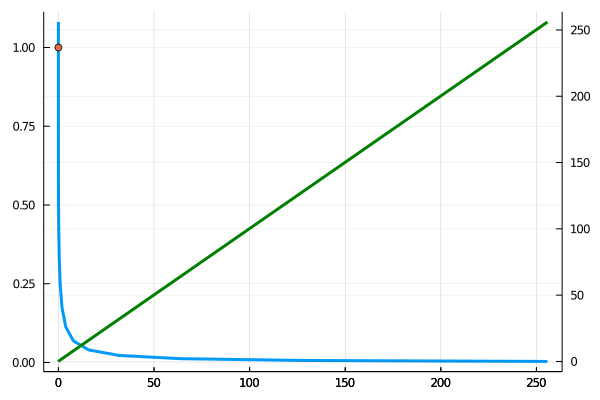

In [16]:
sol = solutionb
plot(sol.trace.γ², sol.trace.k, lw=3, label="")
scatter!([sol.γ²], [sol.k], label="")
plot!(twinx(), sol.trace.γ², sol.trace.δ², lw=3, color=:green, label="")

In [17]:
problem = SpectralProblem(zs, objective, ensemble)
solution = solve(problem, algorithm; chunks_per_thread=1);

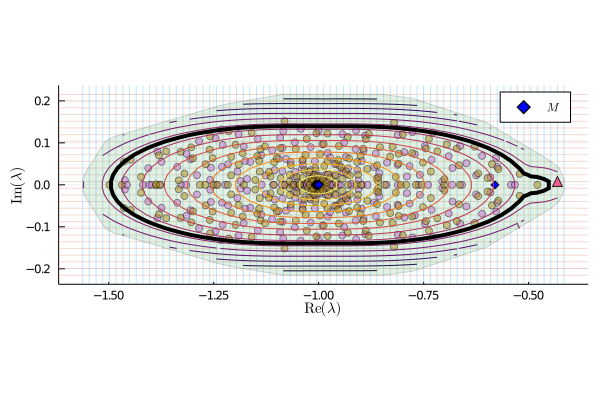

In [18]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(
    p,
    region,
    alpha=0.15,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(jacevs), imag(jacevs), alpha=0.5, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=0.5, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label=L"M")

scatter!(p, xs[[j]], ys[[i]], label="", markershape=:utriangle, markersize=5)

vline!([0.0], color=:black, label="")

contour!(p, xs, ys, solution.γ², alpha=0.15, colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, linewidth=4)

In [19]:
function fpoint(J̃, x₀)
    sol = nlsolve(
        (dx, x) -> network_f!(dx, x, J̃, 0.0),
        (jac, x) -> network_jac!(jac, x, J̃, 0.0),
        x₀;
        method=:newton,
    )
    if !converged(sol)
        error("failed to converge")
    end
    return sol.zero
end

fpoint (generic function with 1 method)

In [20]:
x₀ = x̂
jac = similar(J̃)
σs = 0.0:0.01:1.5
evmaxs = fill(NaN, length(σs))
x₀s = fill(NaN, (length(x₀), length(σs)))
for (i, σ) in enumerate(σs)
    J̃ = Ĵ + σ * J
    x₀s[:, i] = x₀ = fpoint(J̃, x₀)
    network_jac!(jac, x₀, J̃, 0.0)
    evmaxs[i] = maximum(real(eigvals(jac)))
end

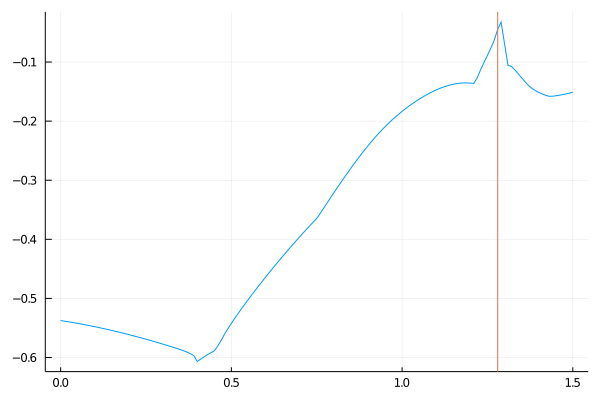

In [21]:
vl = [1.28]
plot(σs, evmaxs, label="")
vline!(vl, label="")

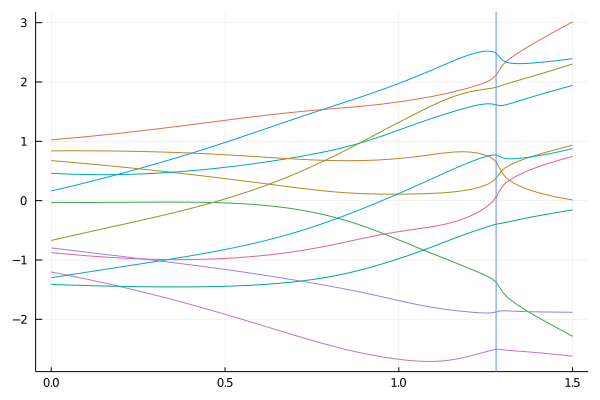

In [22]:
plot(σs, x₀s[1:12, :]', label="")
vline!(vl, label="")

In [23]:
[σs evmaxs]

151×2 Array{Float64,2}:
 0.0   -0.537525
 0.01  -0.538412
 0.02  -0.539331
 0.03  -0.540284
 0.04  -0.54127
 0.05  -0.542288
 0.06  -0.543339
 0.07  -0.544422
 0.08  -0.545538
 0.09  -0.546686
 0.1   -0.547866
 0.11  -0.549077
 0.12  -0.550319
 ⋮     
 1.39  -0.14823
 1.4   -0.151338
 1.41  -0.153951
 1.42  -0.156152
 1.43  -0.157957
 1.44  -0.157868
 1.45  -0.157127
 1.46  -0.156225
 1.47  -0.155168
 1.48  -0.153962
 1.49  -0.15261
 1.5   -0.151115